# Can steady isochrones overturn when both domain boundaries have positive ice thickness?

Yes. The mathematical reason is that positive lateral thickness is not part of the order criterion. The calculation below provides a mechanical example with gravity-driven full-Stokes flow, a linear basal sliding law, and hydrostatic traction on two open boundaries. No velocity is prescribed.

## Assumptions, units, and boundary conditions

The model is two-dimensional, incompressible, and Newtonian. Density is $917\,\mathrm{kg\,m^{-3}}$, viscosity is $2.5\times10^8\,\mathrm{Pa\,yr}$, and gravity acts at a mean surface slope of $0.05$ rad. The flat surface is traction free. The circular bed is impermeable and obeys the linear sliding law $\tau_b=-\beta u_t$, with $\beta=10^5\,\mathrm{Pa\,yr\,m^{-1}}$. Each vertical cut has hydrostatic traction $\boldsymbol{\sigma}\boldsymbol{n}=-\rho g\cos\theta(-z)\boldsymbol{n}$. The surface mass balance needed to keep the surface fixed is diagnosed from the solution.

The maximum ice thickness is 150 m. The calculation varies the thickness at both open boundaries from 23 to 92 m. The predicted observable is the signed material-map Jacobian $J=\left.\partial x/\partial x_0\right|_\tau$. A negative value means that an initially ordered surface-deposition map has passed through vertical.

## Mathematical result

Positive boundary thickness cannot yield a no-overturning theorem. Suppose a steady Stokes solution contains an overturned surface-deposition map, $J(x_0,T)<0$, and its trajectories through age $T$ lie inside a compact part of the ice. Place two transverse cuts outside those trajectories but inside the original domain. On each cut prescribe the traction $\boldsymbol{\sigma}\boldsymbol{n}$ inherited from the original solution. The restricted velocity and pressure solve the same Stokes equations, and the trajectories and $J$ are unchanged. Both cuts have strictly positive ice thickness.

This is an exact existence argument, but inherited tractions could be specially tuned. The calculation below therefore replaces them with hydrostatic tractions and checks the complete power balance.

In [1]:
"""Stokes overturning with a linear sliding law in an open trough."""

from pathlib import Path
import logging
import tempfile
import warnings

warnings.filterwarnings("ignore", message="Unable to import recommended hash")
warnings.filterwarnings("ignore", message="The .*Function.at.* method")
logging.getLogger("tsfc").setLevel(logging.ERROR)

import firedrake as fd
import gmsh
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np
import pandas as pd
from scipy.interpolate import RegularGridInterpolator

plt.rcParams["ps.fonttype"] = 42
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda value: f"{value:.6g}")


DENSITY = 917.0  # kg m^-3
GRAVITY = 9.81  # m s^-2
VISCOSITY = 2.5e8  # Pa yr
SURFACE_SLOPE = 0.05  # rad
BASAL_DRAG = 1.0e5  # Pa yr m^-1
NITSCHE_PENALTY = 3.0e4
RADIUS = 250.0  # m
CENTER_HEIGHT = 100.0  # m
CAP_HALF_WIDTH = np.sqrt(RADIUS**2 - CENTER_HEIGHT**2)
EVOLUTION_AGES = (0.0, 300.0, 600.0, 900.0, 1150.0, 1374.0)


def bed_height(x):
    """Circular bed elevation."""
    return CENTER_HEIGHT - np.sqrt(RADIUS**2 - np.asarray(x) ** 2)


def cap_mesh(cut_fraction, resolution):
    """Truncate the circular cap at two vertical, positive-thickness cuts."""
    side = cut_fraction * CAP_HALF_WIDTH
    bottom_side = float(bed_height(side))
    mesh_file = tempfile.NamedTemporaryFile(suffix=".msh", delete=False).name
    gmsh.initialize()
    gmsh.option.setNumber("General.Terminal", 0)
    gmsh.option.setNumber("Mesh.MshFileVersion", 2.2)
    gmsh.model.add("open_cap")
    left_surface = gmsh.model.geo.addPoint(-side, 0.0, 0.0, resolution)
    left_bed = gmsh.model.geo.addPoint(-side, bottom_side, 0.0, resolution)
    bottom = gmsh.model.geo.addPoint(0.0, CENTER_HEIGHT - RADIUS, 0.0, resolution)
    right_bed = gmsh.model.geo.addPoint(side, bottom_side, 0.0, resolution)
    right_surface = gmsh.model.geo.addPoint(side, 0.0, 0.0, resolution)
    center = gmsh.model.geo.addPoint(0.0, CENTER_HEIGHT, 0.0, resolution)
    bed_left = gmsh.model.geo.addCircleArc(left_bed, center, bottom)
    bed_right = gmsh.model.geo.addCircleArc(bottom, center, right_bed)
    right = gmsh.model.geo.addLine(right_bed, right_surface)
    surface = gmsh.model.geo.addLine(right_surface, left_surface)
    left = gmsh.model.geo.addLine(left_surface, left_bed)
    loop = gmsh.model.geo.addCurveLoop(
        [bed_left, bed_right, right, surface, left]
    )
    area = gmsh.model.geo.addPlaneSurface([loop])
    gmsh.model.geo.synchronize()
    gmsh.model.addPhysicalGroup(1, [bed_left, bed_right], 1)
    gmsh.model.addPhysicalGroup(1, [surface], 2)
    gmsh.model.addPhysicalGroup(1, [left], 3)
    gmsh.model.addPhysicalGroup(1, [right], 4)
    gmsh.model.addPhysicalGroup(2, [area], 1)
    gmsh.model.mesh.generate(2)
    gmsh.write(mesh_file)
    gmsh.finalize()
    linear_mesh = fd.Mesh(mesh_file)
    coordinate_space = fd.VectorFunctionSpace(linear_mesh, "CG", 2)
    coordinates = fd.Function(coordinate_space).interpolate(
        fd.SpatialCoordinate(linear_mesh)
    )
    bed_nodes = fd.DirichletBC(
        coordinate_space, fd.Constant((0.0, 0.0)), 1
    ).nodes
    bed_coordinates = coordinates.dat.data[bed_nodes]
    relative = bed_coordinates - np.array((0.0, CENTER_HEIGHT))
    angle = np.arctan2(relative[:, 1], relative[:, 0])
    coordinates.dat.data[bed_nodes] = np.column_stack(
        (RADIUS * np.cos(angle), CENTER_HEIGHT + RADIUS * np.sin(angle))
    )
    return fd.Mesh(coordinates), side


def solve_stokes(cut_fraction, traction_factor, resolution=7.5):
    """Solve with linear bed drag and hydrostatic open-side traction."""
    mesh, side = cap_mesh(cut_fraction, resolution)
    velocity_space = fd.VectorFunctionSpace(mesh, "CG", 2)
    pressure_space = fd.FunctionSpace(mesh, "CG", 1)
    solution = fd.Function(velocity_space * pressure_space)
    u, p = fd.split(solution)
    v, q = fd.TestFunctions(solution.function_space())
    body_force = fd.Constant(
        (
            DENSITY * GRAVITY * np.sin(SURFACE_SLOPE),
            -DENSITY * GRAVITY * np.cos(SURFACE_SLOPE),
        )
    )
    residual = (
        2.0 * VISCOSITY * fd.inner(fd.sym(fd.grad(u)), fd.sym(fd.grad(v)))
        - p * fd.div(v)
        - q * fd.div(u)
        - fd.dot(body_force, v)
    ) * fd.dx

    normal = fd.FacetNormal(mesh)
    tangent = fd.as_vector((-normal[1], normal[0]))
    stress = 2.0 * VISCOSITY * fd.sym(fd.grad(u)) - p * fd.Identity(2)
    test_stress = (
        2.0 * VISCOSITY * fd.sym(fd.grad(v)) - q * fd.Identity(2)
    )
    normal_speed = fd.dot(u, normal)
    test_normal_speed = fd.dot(v, normal)
    residual += (
        BASAL_DRAG * fd.dot(u, tangent) * fd.dot(v, tangent)
        - fd.dot(stress * normal, normal) * test_normal_speed
        - fd.dot(test_stress * normal, normal) * normal_speed
        + NITSCHE_PENALTY
        * VISCOSITY
        / fd.Constant(resolution)
        * normal_speed
        * test_normal_speed
    ) * fd.ds(1)

    z = fd.SpatialCoordinate(mesh)[1]
    hydrostatic_pressure = -DENSITY * GRAVITY * np.cos(SURFACE_SLOPE) * z
    side_traction = -fd.Constant(traction_factor) * hydrostatic_pressure * normal
    side_measure = fd.ds(3, domain=mesh) + fd.ds(4, domain=mesh)
    residual -= fd.dot(side_traction, v) * side_measure

    fd.solve(
        residual == 0,
        solution,
        solver_parameters={
            "ksp_type": "preonly",
            "pc_type": "lu",
            "pc_factor_mat_solver_type": "mumps",
        },
    )
    velocity, pressure = solution.subfunctions
    bed_length = fd.assemble(fd.Constant(1.0) * fd.ds(1, domain=mesh))
    gravity_power = fd.assemble(fd.dot(body_force, velocity) * fd.dx)
    left_boundary_power = fd.assemble(
        fd.dot(side_traction, velocity) * fd.ds(3, domain=mesh)
    )
    right_boundary_power = fd.assemble(
        fd.dot(side_traction, velocity) * fd.ds(4, domain=mesh)
    )
    boundary_power = left_boundary_power + right_boundary_power
    basal_dissipation = fd.assemble(
        BASAL_DRAG * fd.dot(velocity, tangent) ** 2 * fd.ds(1)
    )
    viscous_dissipation = fd.assemble(
        2.0
        * VISCOSITY
        * fd.inner(fd.sym(fd.grad(velocity)), fd.sym(fd.grad(velocity)))
        * fd.dx
    )
    diagnostics = {
        "cells": mesh.num_cells(),
        "gravity power": gravity_power,
        "left-boundary power": left_boundary_power,
        "right-boundary power": right_boundary_power,
        "side-boundary power": boundary_power,
        "basal dissipation": basal_dissipation,
        "viscous dissipation": viscous_dissipation,
        "relative energy residual": (
            gravity_power
            + boundary_power
            - basal_dissipation
            - viscous_dissipation
        )
        / (abs(gravity_power) + abs(boundary_power)),
        "rms basal normal speed": np.sqrt(
            fd.assemble(fd.dot(velocity, normal) ** 2 * fd.ds(1))
            / bed_length
        ),
        "minimum nodal u": np.min(velocity.dat.data_ro[:, 0]),
        "maximum nodal u": np.max(velocity.dat.data_ro[:, 0]),
    }
    return velocity, side, diagnostics


def make_sampler(velocity, side):
    """Sample the unstructured solution in bed-following coordinates."""
    x = np.linspace(-0.995 * side, 0.995 * side, 501)
    # Deposits start 0.05 m below the surface.  Extend the sampling grid above
    # that level in the thick interior so near-surface queries remain valid.
    sigma = np.linspace(0.005, 0.99995, 181)
    bed = bed_height(x)
    X = np.tile(x, (len(sigma), 1))
    Z = bed[None, :] * (1.0 - sigma[:, None])
    points = np.column_stack((X.ravel(), Z.ravel()))
    values = np.asarray(
        velocity.at(points, tolerance=1.0e-7)
    ).reshape(Z.shape + (2,))
    fields = {
        name: RegularGridInterpolator(
            (sigma, x),
            values[..., component],
            bounds_error=False,
            fill_value=np.nan,
        )
        for component, name in enumerate(("u", "w"))
    }

    def sample(name, x_value, z_value):
        x_values, z_values = np.broadcast_arrays(x_value, z_value)
        local_bed = bed_height(x_values)
        local_sigma = (z_values - local_bed) / (-local_bed)
        points = np.column_stack((local_sigma.ravel(), x_values.ravel()))
        result = fields[name](points).reshape(x_values.shape)
        return float(result) if result.ndim == 0 else result

    return sample, np.nanmin(values[..., 0]), np.nanmax(values[..., 0])


def trace_map(
    sample,
    side,
    maximum_age=5000.0,
    time_step=1.0,
    source_count=301,
    snapshot_ages=(),
):
    """Trace a surface-deposition map until it exits the open domain."""
    sources = np.linspace(-0.96 * side, -0.04 * side, source_count)
    start_z = np.full_like(sources, -0.05)
    accumulation = -sample("w", sources, start_z)
    keep = accumulation > 1.0e-6
    sources = sources[keep]
    state = np.column_stack((sources, start_z[keep]))

    def velocity(values):
        return np.column_stack(
            (
                sample("u", values[:, 0], values[:, 1]),
                sample("w", values[:, 0], values[:, 1]),
            )
        )

    best = {"minimum J": np.inf, "age": np.nan}
    first_resolved_overturn = None
    evolution_snapshots = {}
    minimum_path_u = np.inf
    for age in np.arange(0.0, maximum_age + time_step, time_step):
        local_bed = bed_height(state[:, 0])
        sigma = (state[:, 1] - local_bed) / (-local_bed)
        valid = (
            np.isfinite(state[:, 0])
            & (np.abs(state[:, 0]) < 0.994 * side)
            & (sigma > 0.006)
            & (sigma < 0.9998)
        )
        indices = np.where(valid)[0]
        groups = np.split(indices, np.where(np.diff(indices) > 1)[0] + 1)
        jacobian = np.full(len(sources), np.nan)
        for group in groups:
            if len(group) >= 9:
                interior = group[2:-2]
                jacobian[interior] = (
                    state[interior + 1, 0] - state[interior - 1, 0]
                ) / (sources[interior + 1] - sources[interior - 1])
        finite_jacobian = np.isfinite(jacobian)
        if age in snapshot_ages:
            evolution_snapshots[age] = {
                "states": state.copy(),
                "valid": valid.copy(),
            }
        if np.any(finite_jacobian):
            valid_sources = sources[finite_jacobian]
            snapshot = {
                "minimum J": np.nanmin(jacobian),
                "maximum J": np.nanmax(jacobian),
                "age": age,
                "sources": sources.copy(),
                "states": state.copy(),
                "jacobian": jacobian.copy(),
                "valid": valid.copy(),
                "valid source count": len(valid_sources),
                "valid source span": np.ptp(valid_sources),
            }
            if snapshot["minimum J"] < best["minimum J"]:
                best = snapshot
            if (
                first_resolved_overturn is None
                and snapshot["minimum J"] < -0.20
            ):
                first_resolved_overturn = snapshot
        if not np.any(valid) or age >= maximum_age:
            break
        k1 = velocity(state)
        minimum_path_u = min(minimum_path_u, np.nanmin(k1[valid, 0]))
        k2 = velocity(state + 0.5 * time_step * k1)
        k3 = velocity(state + 0.5 * time_step * k2)
        k4 = velocity(state + time_step * k3)
        state += time_step * (k1 + 2.0 * k2 + 2.0 * k3 + k4) / 6.0
    best["minimum path u"] = minimum_path_u
    best["accumulation range"] = (
        np.min(accumulation[keep]),
        np.max(accumulation[keep]),
    )
    best["deposition source count"] = len(sources)
    best["deposition source span"] = np.ptp(sources)
    best["first resolved overturn"] = first_resolved_overturn
    best["evolution snapshots"] = evolution_snapshots
    return best


def run_case(cut_fraction, resolution, snapshot_ages=()):
    """Solve one domain and evaluate its surface-deposition map."""
    velocity, side, diagnostics = solve_stokes(
        cut_fraction, 1.0, resolution
    )
    sample, minimum_grid_u, maximum_grid_u = make_sampler(velocity, side)
    material_map = trace_map(
        sample, side, snapshot_ages=snapshot_ages
    )
    row = {
        "cut fraction": cut_fraction,
        "target spacing (m)": resolution,
        "boundary thickness (m)": -bed_height(side),
        "minimum J": material_map["minimum J"],
        "age of minimum J (yr)": material_map["age"],
        "minimum grid u (m/yr)": minimum_grid_u,
        "maximum grid u (m/yr)": maximum_grid_u,
        "minimum path u (m/yr)": material_map["minimum path u"],
        "accumulation min (m/yr)": material_map["accumulation range"][0],
        "accumulation max (m/yr)": material_map["accumulation range"][1],
        "deposition source count": material_map["deposition source count"],
        "deposition source span (m)": material_map["deposition source span"],
        "valid source count at minimum": material_map["valid source count"],
        "valid source span at minimum (m)": material_map["valid source span"],
        "first resolved age (yr)": material_map[
            "first resolved overturn"
        ]["age"],
        "first resolved minimum J": material_map[
            "first resolved overturn"
        ]["minimum J"],
        "valid source count when resolved": material_map[
            "first resolved overturn"
        ]["valid source count"],
        "valid source span when resolved (m)": material_map[
            "first resolved overturn"
        ]["valid source span"],
    } | diagnostics
    return row, material_map




firedrake:WARNING OMP_NUM_THREADS is not set or is set to a value greater than 1, we suggest setting OMP_NUM_THREADS=1 to improve performance


## Calculations

The first calculation varies boundary thickness on a 7.5 m mesh. The second repeats the 70 m case from 15 to 5 m target spacing. Figure 9a follows the same deposition origins at 0, 0.30, 0.60, 0.90, 1.15, and 1.374 kyr. The final state is the first with $J_{\min}<-0.20$; all deposition origins remain inside the domain at that age.

Solving cut fraction 0.95.
Solving cut fraction 0.9.
Solving cut fraction 0.85.
Solving cut fraction 0.8.
Solving cut fraction 0.7.

Boundary-thickness sweep
 boundary thickness (m)  minimum J  age of minimum J (yr)  deposition source count  deposition source span (m)  valid source count at minimum  valid source span at minimum (m)  first resolved age (yr)  first resolved minimum J  valid source count when resolved  valid source span when resolved (m)  minimum path u (m/yr)  left-boundary power  right-boundary power  side-boundary power  gravity power  relative energy residual
                22.9583  -0.518114                   2027                      301                     200.259                              5                           2.67011                     1637                  -0.20061                               113                              74.7632               0.113223               304267               -304217              50.0621    3.99226e+06               7.

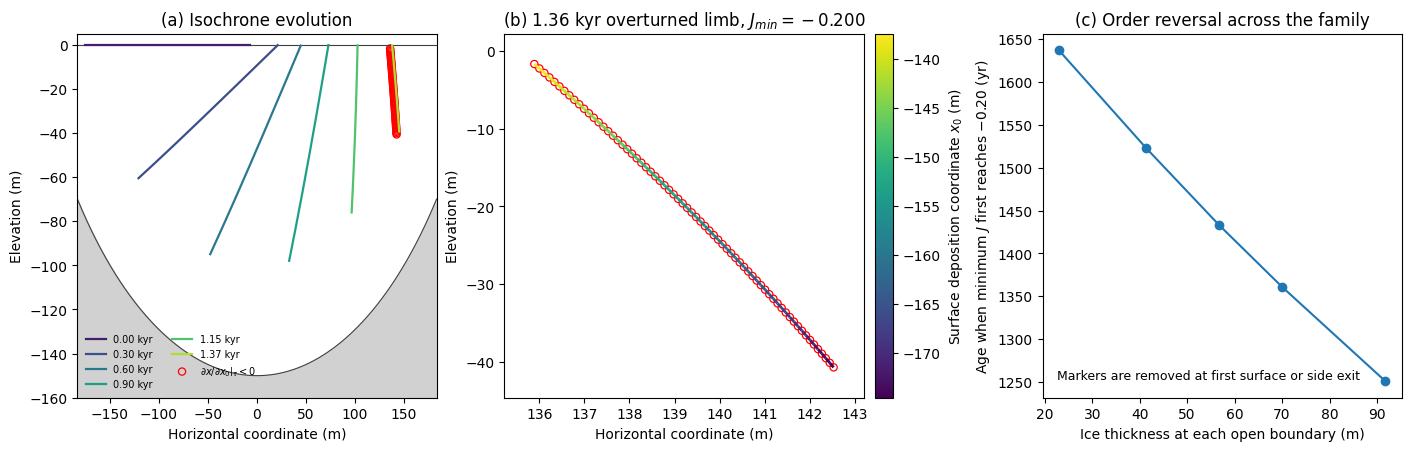

In [2]:
sweep_rows = []
sweep_maps = {}
for cut_fraction in (0.95, 0.90, 0.85, 0.80, 0.70):
    print(f"Solving cut fraction {cut_fraction:g}.", flush=True)
    snapshot_ages = EVOLUTION_AGES if cut_fraction == 0.80 else ()
    row, material_map = run_case(
        cut_fraction, 7.5, snapshot_ages=snapshot_ages
    )
    sweep_rows.append(row)
    sweep_maps[cut_fraction] = material_map
sweep = pd.DataFrame(sweep_rows)
print("\nBoundary-thickness sweep")
print(
    sweep[
        [
            "boundary thickness (m)",
            "minimum J",
            "age of minimum J (yr)",
            "deposition source count",
            "deposition source span (m)",
            "valid source count at minimum",
            "valid source span at minimum (m)",
            "first resolved age (yr)",
            "first resolved minimum J",
            "valid source count when resolved",
            "valid source span when resolved (m)",
            "minimum path u (m/yr)",
            "left-boundary power",
            "right-boundary power",
            "side-boundary power",
            "gravity power",
            "relative energy residual",
        ]
    ].to_string(index=False)
)

convergence_rows = []
for resolution in (15.0, 10.0, 7.5, 5.0):
    if resolution == 7.5:
        row = next(
            item for item in sweep_rows if item["cut fraction"] == 0.80
        )
    else:
        print(f"Solving target spacing {resolution:g} m.", flush=True)
        row, _ = run_case(0.80, resolution)
    convergence_rows.append(row)
convergence = pd.DataFrame(convergence_rows)
print("\nMesh convergence for the 70 m boundary")
print(
    convergence[
        [
            "target spacing (m)",
            "cells",
            "minimum J",
            "age of minimum J (yr)",
            "first resolved age (yr)",
            "first resolved minimum J",
            "valid source count when resolved",
            "rms basal normal speed",
            "relative energy residual",
        ]
    ].to_string(index=False)
)

cut_fraction = 0.80
side = cut_fraction * CAP_HALF_WIDTH
case_map = sweep_maps[cut_fraction]
material_map = case_map["first resolved overturn"]
figure, axes = plt.subplots(
    1, 3, figsize=(14.0, 4.4), constrained_layout=True
)
x = np.linspace(-side, side, 601)
bed = bed_height(x)
axes[0].fill_between(x, bed, -160.0, color="0.82")
axes[0].plot(x, bed, color="0.25", linewidth=0.8)
axes[0].axhline(0.0, color="0.25", linewidth=0.8)
valid = material_map["valid"] & np.isfinite(material_map["jacobian"])
points = material_map["states"][valid]
sources = material_map["sources"][valid]
negative = material_map["jacobian"][valid] < 0.0
snapshot_colors = plt.cm.viridis(
    np.linspace(0.08, 0.88, len(EVOLUTION_AGES))
)
for age, color in zip(EVOLUTION_AGES, snapshot_colors):
    snapshot = case_map["evolution snapshots"][age]
    snapshot_points = snapshot["states"][snapshot["valid"]]
    axes[0].plot(
        snapshot_points[:, 0],
        snapshot_points[:, 1],
        color=color,
        linewidth=1.6,
        label=f"{age / 1000:.2f} kyr",
    )
axes[0].scatter(
    points[negative, 0],
    points[negative, 1],
    s=27,
    facecolors="none",
    edgecolors="red",
    linewidths=0.9,
    label=r"$\left.\partial x/\partial x_0\right|_\tau<0$",
)
axes[0].set(
    xlim=(-side, side),
    ylim=(-160.0, 5.0),
    xlabel="Horizontal coordinate (m)",
    ylabel="Elevation (m)",
    title="(a) Isochrone evolution",
)
axes[0].legend(frameon=False, fontsize=7, loc="lower left", ncol=2)

segments = np.stack((points[:-1], points[1:]), axis=1)
collection = LineCollection(segments, cmap="viridis", linewidth=2.0)
collection.set_array(0.5 * (sources[:-1] + sources[1:]))
axes[1].add_collection(collection)
axes[1].scatter(
    points[negative, 0],
    points[negative, 1],
    s=27,
    facecolors="none",
    edgecolors="red",
    linewidths=0.9,
)
axes[1].autoscale()
axes[1].margins(0.10)
axes[1].set(
    xlabel="Horizontal coordinate (m)",
    ylabel="Elevation (m)",
    title=(
        f"(b) {material_map['age'] / 1000:.2f} kyr overturned limb, "
        f"$J_{{min}}={material_map['minimum J']:.3f}$"
    ),
)
colorbar = figure.colorbar(collection, ax=axes[1], pad=0.02)
colorbar.set_label("Surface deposition coordinate $x_0$ (m)")

axes[2].plot(
    sweep["boundary thickness (m)"],
    sweep["first resolved age (yr)"],
    "o-",
    color="tab:blue",
)
axes[2].set(
    xlabel="Ice thickness at each open boundary (m)",
    ylabel=r"Age when minimum $J$ first reaches $-0.20$ (yr)",
    title="(c) Order reversal across the family",
)
axes[2].text(
    0.04,
    0.05,
    "Markers are removed at first surface or side exit",
    transform=axes[2].transAxes,
    fontsize=9,
)

figure_directory = Path("../figures")
for suffix in ("eps", "pdf"):
    figure.savefig(figure_directory / f"Figure3.{suffix}")
figure.savefig(figure_directory / "Figure3.png", dpi=220)
plt.show()


## Inference and limitation

The calculation shows that zero-thickness margins are not required. In the
70 m case, 301 accumulating origins initially span 168.6 m. Markers are removed
at their first surface or side exit; when $J_{\min}$ first falls below
$-0.20$, the centered order diagnostic retains 68 samples spanning 37.7 m.
Horizontal speed remains positive along the relevant trajectories, so the
result is not a Moffatt eddy.

The hydrostatic cuts carry large but balanced throughflow energy fluxes. On the
7.5 m mesh their powers are $+4.425\times10^6$ and
$-4.426\times10^6\,\mathrm{Pa\,m^2\,yr^{-1}}$, while gravity supplies
$4.634\times10^6\,\mathrm{Pa\,m^2\,yr^{-1}}$. Their small sum is not
evidence that each boundary is dynamically negligible. Basal drag remains
dissipative.

This does not imply that every finite-thickness trough folds. The periodic
geometries tested separately remain ordered over the simulated interval. The
comparison instead predicts that lateral force balance and the locations of
accumulation and ablation control whether a trough supplies enough cumulative
rotation. The circular bed, diagnosed surface balance, hydrostatic open cuts,
two-dimensional flow, and linear rheology remain idealizations.